# **Stock Price Prediction Machine Learning Model**



---



## **Dataset Overview**

*The dataset used in this analysis is loaded from a CSV file "Stocks.csv" that contain data about stock prices.*



---



### **Mount Google Drive to Access Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive




---



In [ ]:
import pandas as pd
import numpy as np
import os
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def norm_ticker(s):
    return s.astype(str).str.strip().str.upper()

## **Phase 1 - Data Collection**

---



# **Import the original dataset**

In [ ]:
FILE_PATH = "/content/drive/MyDrive/all_stock_data.csv"
OUT_PATH  = "/content/drive/MyDrive/sampled_data.csv"
TMP_PATH  = "/content/drive/MyDrive/stock_sample__raw.csv"

In [ ]:
# Dataset is very large (~34M rows), so we stream in chunks to avoid RAM overload.
# We sample by ticker + date window to build a manageable but still time-series-correct dataset.
CHUNK_SIZE = 500_000
START_DATE = "2016-01-01"
END_DATE   = "2020-12-31"

# For next-day prediction labels, last row per ticker can't be labeled (needs t+1).
# So we require MIN_RAW rows to ensure we still have enough labeled rows after shifting.
N_TICKERS = 200

In [ ]:
#IMPORTANT:
# For a next-day label, the last day per ticker has no label and will be dropped later.
# So ensure enough RAW rows per ticker.
LABEL_HORIZON = 1
MIN_LABELED_ROWS_PER_TICKER = 1000
MIN_RAW_ROWS_PER_TICKER = MIN_LABELED_ROWS_PER_TICKER + LABEL_HORIZON  # e.g., 1001

In [ ]:
# Optional: cap rows per ticker after cleaning (None = keep all within date window)
MAX_ROWS_PER_TICKER = None

SEED = 42 # reproducible sampling

In [ ]:
# ----------------------------
# COLUMN DISCOVERY
# ----------------------------
cols = pd.read_csv(FILE_PATH, nrows=0).columns.tolist()

needed = ["Date","Ticker","Open","High","Low","Close","Adj Close","Volume","Dividends","Stock Splits"]
USECOLS = [c for c in needed if c in cols]

if "Date" not in USECOLS or "Ticker" not in USECOLS:
    raise ValueError(f"Your file must contain Date and Ticker. Found columns (first 30): {cols[:30]}")

# We'll read only Date+Ticker in pass 1
PASS1_COLS = ["Date", "Ticker"]

start_ts = pd.Timestamp(START_DATE)
end_ts   = pd.Timestamp(END_DATE)

In [ ]:
# ----------------------------
# PASS 1: Count rows per ticker in date window (streaming)
# ----------------------------
# Why: We only want tickers with enough history to support feature engineering (rolling windows)
# and supervised labels (next-day movement). Streaming keeps memory stable.
ticker_counts = defaultdict(int)

for chunk in pd.read_csv(
    FILE_PATH,
    chunksize=CHUNK_SIZE,
    usecols=PASS1_COLS,
    parse_dates=["Date"],
    low_memory=False
):

    chunk["Ticker"] = norm_ticker(chunk["Ticker"]) # standardize tickers (consistency)
    # Filter date window
    chunk = chunk[(chunk["Date"] >= start_ts) & (chunk["Date"] <= end_ts)]
    if chunk.empty:
        continue

    vc = chunk["Ticker"].value_counts(dropna=False)
    for t, n in vc.items():
        if pd.isna(t):
            continue
        ticker_counts[str(t)] += int(n)

eligible = [t for t, n in ticker_counts.items() if n >= MIN_RAW_ROWS_PER_TICKER]

rng = np.random.default_rng(SEED)
if len(eligible) <= N_TICKERS:
    chosen = eligible
else:
    chosen = rng.choice(eligible, size=N_TICKERS, replace=False).tolist()

chosen = set(chosen)
chosen = set(norm_ticker(pd.Series(list(chosen))))

print("Eligible tickers (>= MIN_RAW_ROWS_PER_TICKER):", len(eligible))
print("Chosen tickers:", len(chosen))
if len(chosen) == 0:
    raise RuntimeError("No tickers met the minimum rows requirement. Lower MIN_LABELED_ROWS_PER_TICKER or widen the date range.")

Eligible tickers (>= MIN_RAW_ROWS_PER_TICKER): 5331
Chosen tickers: 200


In [ ]:
# ----------------------------
# PASS 2: Write chosen tickers within date window (streaming)
# ----------------------------
# Why: We avoid loading the full dataset. We extract only selected tickers + date range,
# then do final cleaning on the smaller extracted dataset.
if os.path.exists(TMP_PATH):
    os.remove(TMP_PATH)

first = True
written = 0

for chunk in pd.read_csv(
    FILE_PATH,
    chunksize=CHUNK_SIZE,
    usecols=USECOLS,
    parse_dates=["Date"],
    low_memory=False
):

    chunk["Ticker"] = norm_ticker(chunk["Ticker"])
    chunk = chunk[(chunk["Date"] >= start_ts) & (chunk["Date"] <= end_ts)]
    if chunk.empty:
        continue

    # Append to temp CSV to build the sample progressively
    out = chunk[chunk["Ticker"].astype(str).isin(chosen)]
    if out.empty:
        continue

    out.to_csv(TMP_PATH, mode="w" if first else "a", header=first, index=False)
    first = False
    written += len(out)

print("Raw rows written to temp:", written)
print("Temp saved:", TMP_PATH)

if written == 0:
    raise RuntimeError("No rows were written. Check that Date format and ticker names match, and your date window contains data.")

Raw rows written to temp: 250521
Temp saved: /content/drive/MyDrive/stock_sample__raw.csv


In [ ]:
# ----------------------------
# FINALIZE: sort + dedupe + enforce minimums
# ----------------------------
# Why: Sorting by (Ticker, Date) is REQUIRED for time-series features (shift/rolling).
# Dedupe prevents duplicate trading days from corrupting rolling stats and labels.
df = pd.read_csv(TMP_PATH, parse_dates=["Date"], low_memory=False)
df["Ticker"] = norm_ticker(df["Ticker"])

# Remove invalid ticker values (data quality)
bad = {"", "NAN", "NONE", "NULL"}
bad_count = df["Ticker"].astype(str).isin(bad).sum()
print("Bad ticker rows:", bad_count)
if bad_count > 0:
    df = df[~df["Ticker"].astype(str).isin(bad)]

# Keep only relevant columns discovered earlier (schema consistency)
df = df[[c for c in USECOLS if c in df.columns]]

# Sort so time-series operations (shift/rolling) are correct
df = df.sort_values(["Ticker", "Date"], kind="mergesort")

# Drop duplicate trading days per ticker (keeps last occurrence)
df = df.drop_duplicates(["Ticker", "Date"], keep="last")

# Drop rows missing core market values (model stability)
essentials = [c for c in ["Open","High","Low","Close","Volume"] if c in df.columns]
if essentials:
    df = df.dropna(subset=essentials, how="any")

# Ensure each ticker still has enough rows AFTER cleaning
counts = df.groupby("Ticker").size()
good_tickers = counts[counts >= MIN_RAW_ROWS_PER_TICKER].index
df = df[df["Ticker"].isin(good_tickers)]

# Optional: cap rows per ticker (keeps most recent rows)
if MAX_ROWS_PER_TICKER is not None:
    df = df.groupby("Ticker", group_keys=False).tail(int(MAX_ROWS_PER_TICKER))

# Overwrite final output
df.to_csv(OUT_PATH, index=False)

# Clean up temp
try:
    os.remove(TMP_PATH)
except:
    pass


Bad ticker rows: 0


In [ ]:
# ----------------------------
# QUICK REPORT (sanity checks for your report)
# ----------------------------
final_counts = df.groupby("Ticker").size()
print("\nFINAL SAMPLE SAVED:", OUT_PATH)
print("Final rows:", len(df))
print("Unique tickers:", df["Ticker"].nunique())
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("\nRows per ticker (after cleaning):")
print(final_counts.describe())

df.head()



FINAL SAMPLE SAVED: /content/drive/MyDrive/sampled_data.csv
Final rows: 250521
Unique tickers: 200
Date range: 2016-01-04 00:00:00 to 2020-12-31 00:00:00

Rows per ticker (after cleaning):
count     200.000000
mean     1252.605000
std        35.034642
min      1006.000000
25%      1259.000000
50%      1259.000000
75%      1259.000000
max      1259.000000
dtype: float64


,Date,Ticker,Open,High,Low,Close,Volume,Dividends,Stock Splits
146,2016-01-04,AAME,4.850087,4.850087,4.636256,4.704293,8300.0,0.0,0.0
278,2016-01-05,AAME,4.665414,4.752890,4.441863,4.441863,4900.0,0.0,0.0
467,2016-01-06,AAME,4.568218,4.568218,4.519620,4.568218,1900.0,0.0,0.0
621,2016-01-07,AAME,4.529340,4.529340,4.286349,4.451583,1700.0,0.0,0.0
956,2016-01-08,AAME,4.490461,4.519620,4.334948,4.334948,6400.0,0.0,0.0


In [ ]:
import pandas as pd
from google.colab import files

XLSX_PATH = "/content/stock_sample.xlsx"

# load the sampled dataset (the one you actually saved)
df = pd.read_csv(OUT_PATH)

# Excel max rows per sheet
EXCEL_LIMIT = 1_048_576

if len(df) > EXCEL_LIMIT:
    df.head(EXCEL_LIMIT).to_excel(XLSX_PATH, index=False)
    print(f"Excel limit: exported first {EXCEL_LIMIT} rows only.")
else:
    df.to_excel(XLSX_PATH, index=False)

files.download(XLSX_PATH)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



---



## **Import the extracted dataset**

In [ ]:
sampled_file_path = '/content/drive/MyDrive/sampled_data.csv'

In [ ]:
# import the extracted dataset from the csv file and save the data into a variable:
sampled_data = pd.read_csv(sampled_file_path)



---



## **Phase2 - Data Preprocessing:**

*This phase focuses on preparing the raw stock data by cleaning, extracting important features, and saving the processed data for use in the prediction model.*

In [ ]:
# Display the first 5 rows:
sampled_data.head()

,Date,Ticker,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2016-01-04,AAME,4.850087,4.850087,4.636256,4.704293,8300.0,0.0,0.0
1,2016-01-05,AAME,4.665414,4.752890,4.441863,4.441863,4900.0,0.0,0.0
2,2016-01-06,AAME,4.568218,4.568218,4.519620,4.568218,1900.0,0.0,0.0
3,2016-01-07,AAME,4.529340,4.529340,4.286349,4.451583,1700.0,0.0,0.0
4,2016-01-08,AAME,4.490461,4.519620,4.334948,4.334948,6400.0,0.0,0.0


In [ ]:
# Display the last 10 rows:
sampled_data.tail(10)

,Date,Ticker,Open,High,Low,Close,Volume,Dividends,Stock Splits
250511,2020-12-17,ZDPY,0.515,0.515,0.450,0.460,13500.0,0.0,0.0
250512,2020-12-18,ZDPY,0.420,0.440,0.420,0.440,200.0,0.0,0.0
250513,2020-12-21,ZDPY,0.430,0.430,0.400,0.420,1500.0,0.0,0.0
250514,2020-12-22,ZDPY,0.410,0.440,0.400,0.440,19800.0,0.0,0.0
250515,2020-12-23,ZDPY,0.415,0.460,0.415,0.460,42000.0,0.0,0.0
250516,2020-12-24,ZDPY,0.380,0.460,0.380,0.460,13600.0,0.0,0.0
250517,2020-12-28,ZDPY,0.460,0.460,0.423,0.447,8800.0,0.0,0.0
250518,2020-12-29,ZDPY,0.422,0.459,0.422,0.459,19300.0,0.0,0.0
250519,2020-12-30,ZDPY,0.433,0.445,0.410,0.440,59500.0,0.0,0.0
250520,2020-12-31,ZDPY,0.305,0.429,0.305,0.429,33400.0,0.0,0.0


In [ ]:
# Check dataset structure, data types, and missing values
sampled_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250521 entries, 0 to 250520
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Date          250521 non-null  object 
 1   Ticker        250521 non-null  object 
 2   Open          250521 non-null  float64
 3   High          250521 non-null  float64
 4   Low           250521 non-null  float64
 5   Close         250521 non-null  float64
 6   Volume        250521 non-null  float64
 7   Dividends     250521 non-null  float64
 8   Stock Splits  250521 non-null  float64
dtypes: float64(7), object(2)
memory usage: 17.2+ MB


In [ ]:
# Compute descriptive statistics to analyze the central tendency and spread of numerical data
sampled_data.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,250521.000000,250521.000000,250521.000000,250521.000000,2.505210e+05,250521.000000,250521.000000
mean,346.324613,360.380908,333.962930,344.898465,9.414803e+05,0.003071,0.000151
std,5630.158738,5990.384728,5379.232176,5618.366443,7.647982e+06,0.257590,0.016299
min,-65.978302,-65.978302,-65.978302,-65.978302,0.000000e+00,0.000000,0.000000
25%,4.870000,4.970264,4.773421,4.864019,3.000000e+03,0.000000,0.000000
50%,16.090000,16.365659,15.842063,16.077599,8.120000e+04,0.000000,0.000000
75%,43.250345,43.820000,42.654689,43.250000,4.596000e+05,0.000000,0.000000
max,342000.000000,465000.000000,286000.000000,370000.000000,9.987904e+08,90.000000,4.415840


In [ ]:
# Display the dataset shape and column names
print("Shape:", sampled_data.shape)
print("Columns:", list(sampled_data.columns))

Shape: (250521, 9)
Columns: ['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']


In [ ]:
# Check if the ticker data is unique
unique_tickers = sampled_data['Ticker'].nunique()
total_rows = sampled_data.shape[0]

print("Number of unique tickers:", unique_tickers)
print("Total number of rows:", total_rows)

Number of unique tickers: 200
Total number of rows: 250521


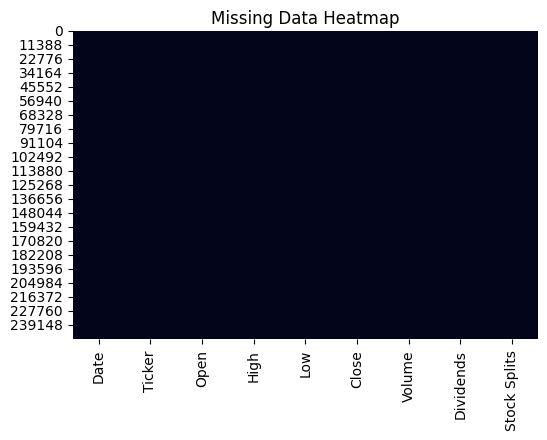

In [ ]:
# Visual heatmap of missing data
plt.figure(figsize=(6,4))
sns.heatmap(sampled_data.isnull(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()

In [ ]:
# Calculating null values in each column
sampled_data.isnull().sum()

,0
Date,0
Ticker,0
Open,0
High,0
Low,0
Close,0
Volume,0
Dividends,0
Stock Splits,0


In [ ]:
for col in sampled_data.select_dtypes(include=['int64', 'float64']).columns:
    neg_count = (sampled_data[col] < 0).sum()
    print(f"{col}: {neg_count} negative values")

Open: 633 negative values
High: 633 negative values
Low: 633 negative values
Close: 633 negative values
Volume: 0 negative values
Dividends: 0 negative values
Stock Splits: 0 negative values


In [ ]:
price_columns = ['Open', 'High', 'Low', 'Close']

# function to check negative values occurance
def has_negative(row):
    return any(row[col] < 0 for col in price_columns)

# Apply the function and get indices
indices_to_drop = sampled_data[sampled_data.apply(has_negative, axis=1)].index

print(f"Dropping {len(indices_to_drop)} rows")
sampled_data = sampled_data.drop(indices_to_drop)

Dropping 633 rows


In [ ]:
# Count zeros in numeric columns
numeric_cols = sampled_data.select_dtypes(include=['int64', 'float64']).columns
zero_counts = (sampled_data[numeric_cols] == 0).sum()
print(zero_counts)

Open                 0
High                 0
Low                  0
Close                0
Volume           33453
Dividends       247846
Stock Splits    249843
dtype: int64


In [ ]:
# These columns are examined because they may contain many or only zero values,
# which can reduce their usefulness for prediction or analysis
columns_to_check = ['Volume','Dividends', 'Stock Splits']

# Loop through each selected column
for col in columns_to_check:

  # Check if all values in the column are equal to zero
  # This helps identify columns that do not provide any meaningful variation
    if (sampled_data[col] == 0).all():
        print("Column", col, "contains only zeros.")
    else:
        print("Column", col, "contains other values besides zero.")

Column Volume contains other values besides zero.
Column Dividends contains other values besides zero.
Column Stock Splits contains other values besides zero.


In [ ]:
# These columns are checked to understand how much useful information they contain
columns_to_check = ['Volume','Dividends','Stock Splits']

for col in columns_to_check:
    total = len(sampled_data)  # total rows
    non_zero_count = (sampled_data[col] != 0).sum()  # count of rows that are NOT zero
    percentage = (non_zero_count / total) * 100
    print(f"Column '{col}' has {non_zero_count} non-zero values out of {total} ({percentage:.2f}%)")


Column 'Volume' has 216435 non-zero values out of 249888 (86.61%)
Column 'Dividends' has 2042 non-zero values out of 249888 (0.82%)
Column 'Stock Splits' has 45 non-zero values out of 249888 (0.02%)


In [ ]:
# Drop Stock Splits and Dividends
sampled_data = sampled_data.drop(columns=['Stock Splits', 'Dividends'], errors="ignore")

# Confirm removal
print(sampled_data.columns)


Index(['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')


In [ ]:
sampled_data['Volume'] = sampled_data['Volume'].replace(0, np.nan)

In [ ]:
print("Zeros remaining in Volume:", (sampled_data['Volume'] == 0).sum())
print("NaN in Volume:", sampled_data['Volume'].isna().sum())
print("Data type of Volume:", sampled_data['Volume'].dtype)

Zeros remaining in Volume: 0
NaN in Volume: 33453
Data type of Volume: float64


In [ ]:
sampled_data.columns

Index(['Date', 'Ticker', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

In [ ]:
numeric_cols = sampled_data.select_dtypes(include=['int64', 'float64']).columns
zero_counts = (sampled_data[numeric_cols] == 0).sum()
print(zero_counts)


Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [ ]:
sampled_data["Date"] = pd.to_datetime(sampled_data["Date"], errors="coerce")
sampled_data = sampled_data.dropna(subset=["Date"])

In [ ]:
sampled_data = sampled_data.sort_values(["Ticker", "Date"]).reset_index(drop=True)

In [ ]:
sampled_data = sampled_data.drop_duplicates(subset=["Ticker", "Date"], keep="last").reset_index(drop=True)

In [ ]:
# Volume cleaning (done once): treat 0 as missing and fill within each ticker only
sampled_data["Volume"] = sampled_data["Volume"].replace(0, np.nan)
sampled_data["Volume"] = sampled_data.groupby("Ticker")["Volume"].ffill()

In [ ]:
#Check if the dataset contain duplicated rows
print("Number of duplicate rows:", sampled_data.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
duplicate_rows = sampled_data[sampled_data.duplicated()]
print(duplicate_rows)

Empty DataFrame
Columns: [Date, Ticker, Open, High, Low, Close, Volume]
Index: []


In [ ]:
# Verify
print("Number of duplicate rows:", sampled_data.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
sampled_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249888 entries, 0 to 249887
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   Date    249888 non-null  datetime64[ns]
 1   Ticker  249888 non-null  object        
 2   Open    249888 non-null  float64       
 3   High    249888 non-null  float64       
 4   Low     249888 non-null  float64       
 5   Close   249888 non-null  float64       
 6   Volume  248330 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 13.3+ MB


In [ ]:
#Check for duplicates
duplicates = sampled_data.duplicated()
print("Duplicated rows:\n", sampled_data[duplicates])

#Check for zero values
zero_values = (sampled_data == 0).sum()
print("\nZero values per column:\n", zero_values)

#Check for NaN or null values
nan_values = sampled_data.isna().sum()
print("\nNaN / Null values per column:\n", nan_values)

#Check for negative values (numeric columns only)
numeric_cols = sampled_data.select_dtypes(include='number').columns
negative_values = (sampled_data[numeric_cols] < 0).sum()
print("\nNegative values per numeric column:\n", negative_values)
print()

# Check for duplicate rows
duplicates = sampled_data.duplicated()  # Returns True for duplicated rows
print("Number of duplicate rows:", duplicates.sum())  # Total count

Duplicated rows:
 Empty DataFrame
Columns: [Date, Ticker, Open, High, Low, Close, Volume]
Index: []

Zero values per column:
 Date      0
Ticker    0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

NaN / Null values per column:
 Date         0
Ticker       0
Open         0
High         0
Low          0
Close        0
Volume    1558
dtype: int64

Negative values per numeric column:
 Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Number of duplicate rows: 0




---



## **Phase3 - Feature** **Engineering:**

*This phase focuses on creating and selecting useful features from the data to help the stock prediction model learn patterns more accurately.*

In [ ]:
# Verify Date column datatype before feature engineering
print("Date column type:", sampled_data['Date'].dtype)



Date column type: datetime64[ns]


In [ ]:
# Extract time-based features from Date
sampled_data['Year'] = sampled_data['Date'].dt.year
sampled_data['Month'] = sampled_data['Date'].dt.month
sampled_data['Day'] = sampled_data['Date'].dt.day
sampled_data['DayOfWeek'] = sampled_data['Date'].dt.dayofweek

# Display extracted time features
sampled_data[['Date', 'Year', 'Month', 'Day', 'DayOfWeek']].head()


,Date,Year,Month,Day,DayOfWeek
0,2016-01-04,2016,1,4,0
1,2016-01-05,2016,1,5,1
2,2016-01-06,2016,1,6,2
3,2016-01-07,2016,1,7,3
4,2016-01-08,2016,1,8,4


In [ ]:
# Calculate daily price range (High - Low)
sampled_data['Price_Range'] = sampled_data['High'] - sampled_data['Low']

# Calculate difference between Close and Open price
sampled_data['Open_Close_Diff'] = sampled_data['Close'] - sampled_data['Open']

# Display price movement features
sampled_data[['Open', 'High', 'Low', 'Close', 'Price_Range', 'Open_Close_Diff']].head()


,Open,High,Low,Close,Price_Range,Open_Close_Diff
0,4.850087,4.850087,4.636256,4.704293,0.213831,-0.145794
1,4.665414,4.752890,4.441863,4.441863,0.311027,-0.223551
2,4.568218,4.568218,4.519620,4.568218,0.048598,0.000000
3,4.529340,4.529340,4.286349,4.451583,0.242990,-0.077757
4,4.490461,4.519620,4.334948,4.334948,0.184673,-0.155514


In [ ]:
# Daily returns MUST be computed per ticker
sampled_data["Daily_Return"] = sampled_data.groupby("Ticker")["Close"].pct_change()

sampled_data[['Close', 'Daily_Return']].head(10)


,Close,Daily_Return
0,4.704293,NaN
1,4.441863,-0.055785
2,4.568218,0.028446
3,4.451583,-0.025532
4,4.334948,-0.026201
5,4.140555,-0.044843
6,4.159996,0.004695
7,4.266910,0.025701
8,4.296069,0.006834
9,4.325228,0.006787


In [ ]:
# Rolling features MUST be computed per ticker
sampled_data["MA_5"]  = sampled_data.groupby("Ticker")["Close"].transform(lambda s: s.rolling(5).mean())
sampled_data["MA_10"] = sampled_data.groupby("Ticker")["Close"].transform(lambda s: s.rolling(10).mean())

sampled_data["STD_5"] = sampled_data.groupby("Ticker")["Close"].transform(lambda s: s.rolling(5).std())

sampled_data["Volume_Change"] = sampled_data.groupby("Ticker")["Volume"].pct_change()
sampled_data["Volume_MA_5"]   = sampled_data.groupby("Ticker")["Volume"].transform(lambda s: s.rolling(5).mean())


/tmp/ipython-input-4178505991.py:7: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  sampled_data["Volume_Change"] = sampled_data.groupby("Ticker")["Volume"].pct_change()


In [ ]:
# Display volume features
sampled_data[['Volume', 'Volume_Change', 'Volume_MA_5']].head(10)

,Volume,Volume_Change,Volume_MA_5
0,8300.0,NaN,NaN
1,4900.0,-0.409639,NaN
2,1900.0,-0.612245,NaN
3,1700.0,-0.105263,NaN
4,6400.0,2.764706,4640.0
5,1400.0,-0.781250,3260.0
6,900.0,-0.357143,2460.0
7,2200.0,1.444444,2520.0
8,3100.0,0.409091,2800.0
9,14200.0,3.580645,4360.0


In [ ]:
# Drop rows where rolling features are not available yet
needed = ["Daily_Return","MA_10","STD_5","Volume_Change","Volume_MA_5"]
sampled_data = sampled_data.dropna(subset=needed).reset_index(drop=True)


In [ ]:
# Display final dataset structure
sampled_data.info()

# Preview final engineered dataset
sampled_data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246646 entries, 0 to 246645
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Date             246646 non-null  datetime64[ns]
 1   Ticker           246646 non-null  object        
 2   Open             246646 non-null  float64       
 3   High             246646 non-null  float64       
 4   Low              246646 non-null  float64       
 5   Close            246646 non-null  float64       
 6   Volume           246646 non-null  float64       
 7   Year             246646 non-null  int32         
 8   Month            246646 non-null  int32         
 9   Day              246646 non-null  int32         
 10  DayOfWeek        246646 non-null  int32         
 11  Price_Range      246646 non-null  float64       
 12  Open_Close_Diff  246646 non-null  float64       
 13  Daily_Return     246646 non-null  float64       
 14  MA_5             246

,Date,Ticker,Open,High,Low,Close,Volume,Year,Month,Day,DayOfWeek,Price_Range,Open_Close_Diff,Daily_Return,MA_5,MA_10,STD_5,Volume_Change,Volume_MA_5
0,2016-01-15,AAME,4.422425,4.422425,4.082238,4.325228,14200.0,2016,1,15,4,0.340187,-0.097197,0.006787,4.237752,4.368966,0.082759,3.580645,4360.0
1,2016-01-19,AAME,4.539060,4.539060,4.480742,4.480742,1100.0,2016,1,19,1,0.058318,-0.058318,0.035955,4.305789,4.346611,0.116026,-0.922535,4300.0
2,2016-01-20,AAME,4.432144,4.548779,3.294949,3.819808,18600.0,2016,1,20,2,1.253830,-0.612336,-0.147506,4.237752,4.284406,0.247803,15.909091,7840.0
3,2016-01-21,AAME,4.004481,4.189154,3.887846,4.101677,3300.0,2016,1,21,3,0.301308,0.097196,0.073791,4.204705,4.237752,0.253885,-0.822581,8060.0
4,2016-01-22,AAME,4.101677,4.159996,3.975323,4.159996,1400.0,2016,1,22,4,0.184673,0.058318,0.014218,4.177490,4.208593,0.248887,-0.575758,7720.0


Outlier detection

In [ ]:
numeric_cols = sampled_data.select_dtypes(include='number').columns
Q1 = sampled_data[numeric_cols].quantile(0.25)
Q3 = sampled_data[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Detect outliers
outliers = ((sampled_data[numeric_cols] < (Q1 - 1.5 * IQR)) |
            (sampled_data[numeric_cols] > (Q3 + 1.5 * IQR)))

# Show rows that have any outliers
outlier_rows = sampled_data[outliers.any(axis=1)]
print("Outlier rows:\n", outlier_rows)


Outlier rows:
              Date Ticker      Open      High       Low     Close   Volume  \
0      2016-01-15   AAME  4.422425  4.422425  4.082238  4.325228  14200.0   
1      2016-01-19   AAME  4.539060  4.539060  4.480742  4.480742   1100.0   
2      2016-01-20   AAME  4.432144  4.548779  3.294949  3.819808  18600.0   
3      2016-01-21   AAME  4.004481  4.189154  3.887846  4.101677   3300.0   
8      2016-01-28   AAME  4.218313  4.344667  4.198874  4.325228   1400.0   
...           ...    ...       ...       ...       ...       ...      ...   
246637 2020-12-18   ZDPY  0.420000  0.440000  0.420000  0.440000    200.0   
246638 2020-12-21   ZDPY  0.430000  0.430000  0.400000  0.420000   1500.0   
246639 2020-12-22   ZDPY  0.410000  0.440000  0.400000  0.440000  19800.0   
246640 2020-12-23   ZDPY  0.415000  0.460000  0.415000  0.460000  42000.0   
246644 2020-12-30   ZDPY  0.433000  0.445000  0.410000  0.440000  59500.0   

        Year  Month  Day  DayOfWeek  Price_Range  Open_Close

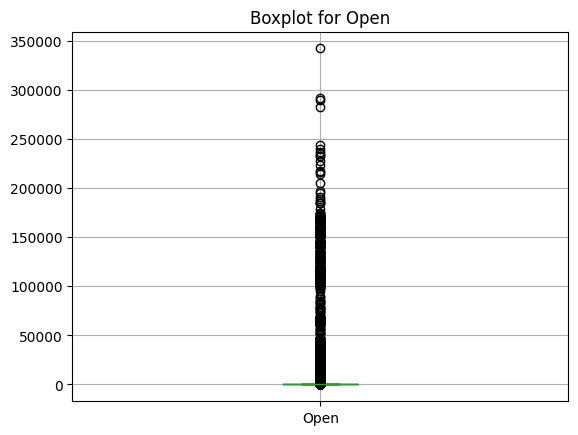

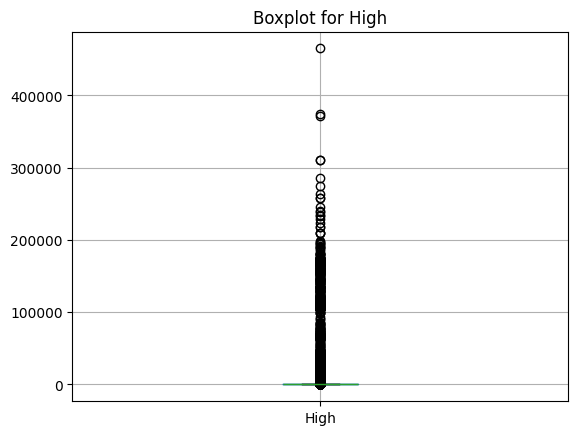

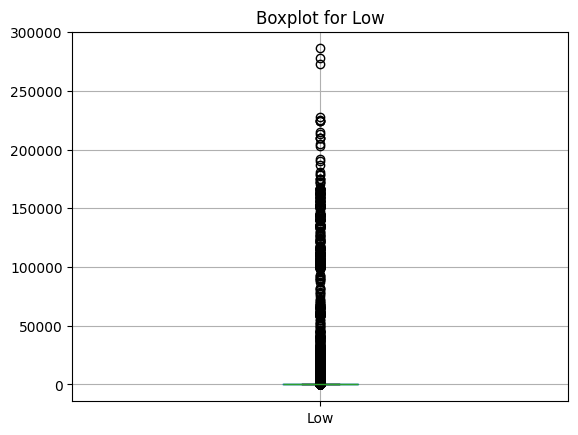

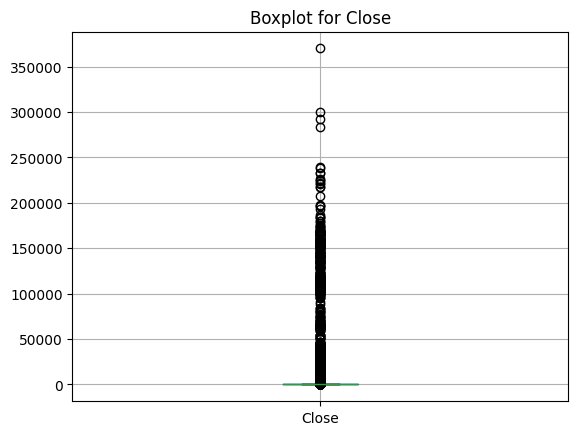

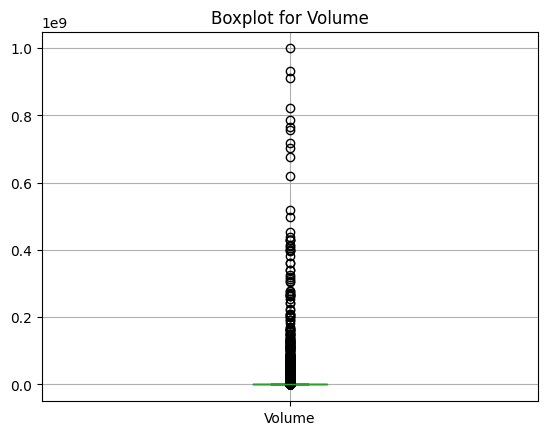

In [ ]:
numeric_cols = ['Open', 'High', 'Low', 'Close', 'Volume']

for col in numeric_cols:
    plt.figure()
    sampled_data.boxplot(column=col)
    plt.title(f'Boxplot for {col}')
    plt.show()

In [ ]:
# ----------------------------
# Supervised target (next-day movement, 3-class)
# 0=Down, 1=Stable, 2=Up
# ----------------------------
sampled_data = sampled_data.sort_values(["Ticker","Date"]).reset_index(drop=True)

sampled_data["Next_Close"] = sampled_data.groupby("Ticker")["Close"].shift(-1)
sampled_data["Next_Return"] = (sampled_data["Next_Close"] - sampled_data["Close"]) / sampled_data["Close"]

EPS = 0.001  # 0.1% stable band

sampled_data["Target_Move"] = np.select(
    [sampled_data["Next_Return"] > EPS,
     sampled_data["Next_Return"] < -EPS],
    [2, 0],
    default=1
).astype(int)

# last row per ticker has no label
sampled_data = sampled_data.dropna(subset=["Next_Close"]).reset_index(drop=True)

# **Phase 4 & 5- Model Design and Evaluation**

# **Supervised Learning**

In [ ]:
# ============================================================
# SUPERVISED LEARNING: Next-day direction classification
# Models: Logistic Regression, Random Forest, Gradient Boosting
# ============================================================

# - Imports for building a clean preprocessing+model pipeline and evaluating classifiers
# - Fixed seed for reproducible results

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)

from sklearn.inspection import permutation_importance
import joblib


SEED = 42
np.random.seed(SEED)

In [ ]:
# ----------------------------
# 1) Safety checks (time-series correctness)
# ----------------------------
# Make sure Date is valid and usable for time-based splitting/ordering
sampled_data["Date"] = pd.to_datetime(sampled_data["Date"], errors="coerce")
sampled_data = sampled_data.dropna(subset=["Date"]).copy()

# Sort by Ticker then Date so shifts/rolling/targets follow real time order (no leakage)
sampled_data = sampled_data.sort_values(["Ticker", "Date"]).reset_index(drop=True)

# Ensure the supervised target exists and is correctly encoded as 3 classes (0/1/2)
assert "Target_Move" in sampled_data.columns, "Target_Move not found. Create it before supervised training."
assert sampled_data["Target_Move"].dropna().isin([0, 1, 2]).all(), "Target_Move must be 0/1/2."

# Quick sanity outputs (size, date coverage, class balance)
print("Rows:", len(sampled_data))
print("Date range:", sampled_data["Date"].min(), "to", sampled_data["Date"].max())
print("Target distribution:\n", sampled_data["Target_Move"].value_counts(normalize=True).rename("ratio"))

Rows: 246446
Date range: 2016-01-15 00:00:00 to 2020-12-30 00:00:00
Target distribution:
 Target_Move
2    0.398347
0    0.377677
1    0.223976
Name: ratio, dtype: float64


In [ ]:
# ----------------------------
# 2) Define features (X) and label (y)
# ----------------------------
# Remove columns that would leak future info (Next_*) or are identifiers/labels
drop_cols = {"Ticker", "Next_Close", "Next_Return", "Target_Move", "Date"}
existing_drop_cols = [c for c in drop_cols if c in sampled_data.columns]

# Keep ticker out of features to avoid the model "memorizing" ticker behavior
use_ticker_as_feature = False
cat_cols = []  # empty on purpose

# X = input features, y = target class (0/1/2)
X = sampled_data.drop(columns=existing_drop_cols, errors="ignore")
y = sampled_data["Target_Move"].astype(int)

# Numeric columns used for scaling/modeling
num_cols = [c for c in X.columns if c not in cat_cols]

print("\nNumeric features:", len(num_cols))
print("Categorical features:", cat_cols)


Numeric features: 17
Categorical features: []


In [ ]:
# ----------------------------
# 3) Time-based split (NO random split!)
# ----------------------------
# Split by time to respect time-series ordering and avoid leakage
max_year = sampled_data["Date"].dt.year.max()
min_year = sampled_data["Date"].dt.year.min()

# Require enough history for a 3-way split (Train / Val / Test)
assert (max_year - min_year) >= 2, (
    f"Not enough years for Train/Val/Test split. Date range years: {min_year} to {max_year}"
)

# Use last year as Test, previous year as Val, remaining years as Train
val_year = max_year - 1
train_year_end = val_year - 1

train_end = pd.Timestamp(f"{train_year_end}-12-31")
val_end   = pd.Timestamp(f"{val_year}-12-31")

print("Auto split years:")
print("Train <= ", train_end.date(), "| Val <= ", val_end.date(), "| Test > ", val_end.date())

# Create masks using Date boundaries
train_mask = sampled_data["Date"] <= train_end
val_mask   = (sampled_data["Date"] > train_end) & (sampled_data["Date"] <= val_end)
test_mask  = sampled_data["Date"] > val_end

# Apply the split to X and y
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val,   y_val   = X.loc[val_mask],   y.loc[val_mask]
X_test,  y_test  = X.loc[test_mask],  y.loc[test_mask]

print("\nSplit sizes:")
print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)

# Ensure each split has data (prevents training/evaluation crashes)
assert len(X_train) > 0, "Train split is empty."
assert len(X_val) > 0, "Validation split is empty."
assert len(X_test) > 0, "Test split is empty."

Auto split years:
Train <=  2018-12-31 | Val <=  2019-12-31 | Test >  2019-12-31

Split sizes:
Train: (146381, 17)  Val: (49953, 17)  Test: (50112, 17)


In [ ]:
# ----------------------------
# 4) Preprocessing pipeline
# ----------------------------
# Numeric: fill missing values then scale robustly (less sensitive to outliers)
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Categorical: fill missing values then one-hot encode (safe for unseen categories)
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numeric + categorical preprocessing into one transformer (used inside model pipelines)
preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ],
    remainder="drop"
)

In [ ]:
# ----------------------------
# 5) Candidate supervised models
# ----------------------------
# Compare multiple supervised classifiers (baseline + non-linear) for the same task
models = {
    "LogisticRegression": LogisticRegression(
        max_iter=2000,                 # ensure convergence
        class_weight="balanced",       # handle class imbalance across 0/1/2
        random_state=SEED
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=400,              # stronger ensemble (more stable results)
        max_depth=None,                # allow model to learn non-linear patterns
        min_samples_leaf=10,           # reduce overfitting/noise
        class_weight="balanced_subsample",  # imbalance handling per tree bootstrap
        n_jobs=-1,                     # faster training
        random_state=SEED
    ),
    "GradientBoosting": GradientBoostingClassifier(
        random_state=SEED              # boosting baseline (often strong on tabular data)
    )
}

def evaluate_multiclass(model_name, pipeline, X_eval, y_eval):
    # Predict classes and (if available) predicted probabilities
    pred = pipeline.predict(X_eval)
    proba = pipeline.predict_proba(X_eval) if hasattr(pipeline, "predict_proba") else None

    # Core evaluation metrics (macro averages treat all classes equally)
    acc  = accuracy_score(y_eval, pred)
    prec = precision_score(y_eval, pred, average="macro", zero_division=0)
    rec  = recall_score(y_eval, pred, average="macro", zero_division=0)
    f1   = f1_score(y_eval, pred, average="macro", zero_division=0)

    # ROC-AUC (One-vs-Rest) uses probabilities to evaluate ranking quality across 3 classes
    auc = np.nan
    if proba is not None:
      auc = roc_auc_score(y_eval, proba, multi_class="ovr")

    # Print summary for comparison across models
    print(f"\n--- {model_name} ---")
    print(f"Accuracy      : {acc:.4f}")
    print(f"Precision(M)  : {prec:.4f}")
    print(f"Recall(M)     : {rec:.4f}")
    print(f"F1(Macro)     : {f1:.4f}")
    print(f"ROC-AUC(OVR)  : {auc:.4f}")

    return {
        "model": model_name,
        "accuracy": acc,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "roc_auc_ovr": auc
    }

In [ ]:
# ----------------------------
# 6) Train + validate (choose best by F1)
# ----------------------------
# Train each candidate model using the same preprocessing, then compare on Validation
results = []
trained_pipelines = {}

for name, clf in models.items():
    # Full pipeline = preprocessing + model (keeps evaluation consistent and leak-free)
    pipe = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", clf)
    ])
    pipe.fit(X_train, y_train)

    # Validate and store metrics for fair comparison
    res = evaluate_multiclass(name, pipe, X_val, y_val)
    results.append(res)
    trained_pipelines[name] = pipe

# Collect results in a table for easy comparison
results_df = pd.DataFrame(results)

# If ROC-AUC could not be computed, push those models lower in ranking
results_df["roc_auc_ovr"] = results_df["roc_auc_ovr"].fillna(-1)

# Select best model based on Macro-F1 (primary) and ROC-AUC (tie-breaker)
results_df = results_df.sort_values(by=["f1_macro", "roc_auc_ovr"], ascending=False)

print("\nValidation comparison (sorted by F1 then ROC-AUC):")
print(results_df)

# Save the best-performing validation model for final testing
best_name = results_df.iloc[0]["model"]
best_pipe = trained_pipelines[best_name]
print("\nBest model on VALIDATION:", best_name)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



--- LogisticRegression ---
Accuracy      : 0.3876
Precision(M)  : 0.5520
Recall(M)     : 0.3492
F1(Macro)     : 0.2492
ROC-AUC(OVR)  : 0.5618

--- RandomForest ---
Accuracy      : 0.5065
Precision(M)  : 0.5214
Recall(M)     : 0.5335
F1(Macro)     : 0.5264
ROC-AUC(OVR)  : 0.7056

--- GradientBoosting ---
Accuracy      : 0.5144
Precision(M)  : 0.5402
Recall(M)     : 0.5334
F1(Macro)     : 0.5363
ROC-AUC(OVR)  : 0.7070

Validation comparison (sorted by F1 then ROC-AUC):
                model  accuracy  precision_macro  recall_macro  f1_macro  \
2    GradientBoosting  0.514444         0.540151      0.533387  0.536311   
1        RandomForest  0.506516         0.521361      0.533468  0.526355   
0  LogisticRegression  0.387584         0.552020      0.349197  0.249205   

   roc_auc_ovr  
2     0.707045  
1     0.705641  
0     0.561809  

Best model on VALIDATION: GradientBoosting


In [ ]:
# Baseline (majority-class) accuracy:
# Shows the accuracy you get by always predicting the most common class.
# Used to confirm the ML models actually beat a simple naive baseline.
baseline_acc = y_val.value_counts(normalize=True).max()
print("Baseline accuracy (majority class):", baseline_acc)

Baseline accuracy (majority class): 0.4089644265609673



FINAL TEST RESULTS: GradientBoosting
              precision    recall  f1-score   support

           0     0.4807    0.2543    0.3327     20127
           1     0.6821    0.6787    0.6804      9160
           2     0.4906    0.7150    0.5819     20825

    accuracy                         0.5233     50112
   macro avg     0.5512    0.5493    0.5317     50112
weighted avg     0.5216    0.5233    0.4998     50112

Confusion Matrix:
 [[ 5119  1500 13508]
 [  990  6217  1953]
 [ 4539  1397 14889]]


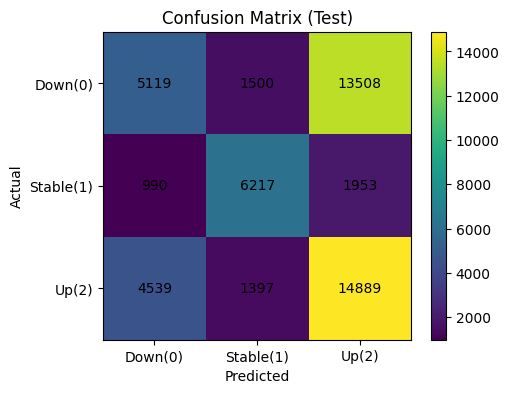

Test ROC-AUC (OVR): 0.7118


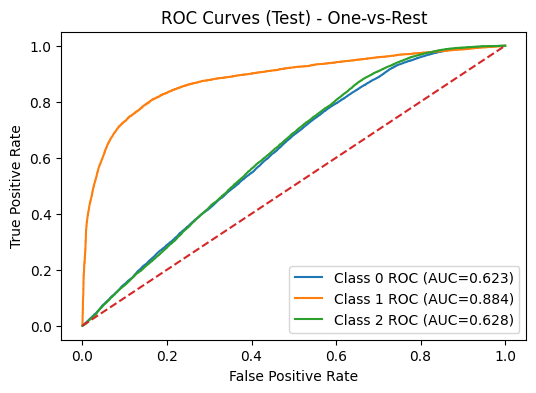

In [ ]:
# ----------------------------
# 7) Refit best model on Train+Val, then final TEST evaluation
# ----------------------------
# Retrain using Train+Validation to use the maximum past data before final testing
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

best_pipe.fit(X_trainval, y_trainval)

# Final predictions on the held-out Test set (never used in training/selection)
test_pred = best_pipe.predict(X_test)
test_proba = best_pipe.predict_proba(X_test) if hasattr(best_pipe, "predict_proba") else None

print("\n==============================")
print("FINAL TEST RESULTS:", best_name)
print("==============================")
print(classification_report(y_test, test_pred, digits=4))

# Confusion matrix: shows which classes are being confused (Down/Stable/Up)
cm = confusion_matrix(y_test, test_pred, labels=[0, 1, 2])
print("Confusion Matrix:\n", cm)

# Confusion matrix plot (matplotlib only)
plt.figure(figsize=(5,4))
plt.imshow(cm)
plt.title("Confusion Matrix (Test)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.xticks([0,1,2], ["Down(0)", "Stable(1)", "Up(2)"])
plt.yticks([0,1,2], ["Down(0)", "Stable(1)", "Up(2)"])
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha="center", va="center")
plt.show()

# ROC-AUC + ROC curves (One-vs-Rest) using predicted probabilities for 3-class classification
if test_proba is not None:
    test_auc = roc_auc_score(y_test, test_proba, multi_class="ovr")
    print(f"Test ROC-AUC (OVR): {test_auc:.4f}")

    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    classes = [0, 1, 2]
    y_test_bin = label_binarize(y_test, classes=classes)

    plt.figure(figsize=(6,4))
    for i, cls in enumerate(classes):
        # Skip ROC curve if this class is missing in the Test labels
        if y_test_bin[:, i].sum() == 0 or y_test_bin[:, i].sum() == len(y_test_bin):
            continue

        fpr, tpr, _ = roc_curve(y_test_bin[:, i], test_proba[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Class {cls} ROC (AUC={roc_auc:.3f})")

    plt.plot([0,1], [0,1], linestyle="--")
    plt.title("ROC Curves (Test) - One-vs-Rest")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

In [ ]:
# ----------------------------
# Feature importance (Permutation Importance) - use TEST set
# ----------------------------
# Measure which features matter most by shuffling each feature and checking
# how much the model’s Macro-F1 drops (model-agnostic interpretability)
X_imp = X_test.copy()
y_imp = y_test.copy()

perm = permutation_importance(
    best_pipe,
    X_imp, y_imp,
    n_repeats=5,           # repeat shuffling to reduce randomness
    random_state=SEED,     # reproducible results
    n_jobs=-1,             # faster execution
    scoring="f1_macro"     # match the main selection metric
)

# Rank features by average importance across repeats (higher = more important)
importances = pd.Series(perm.importances_mean, index=X_imp.columns).sort_values(ascending=False)
print("\nTop 15 important features (permutation importance):")
print(importances.head(15))


Top 15 important features (permutation importance):
Price_Range        0.086663
Daily_Return       0.011354
Volume_MA_5        0.010593
Low                0.006187
Month              0.002168
MA_5               0.001228
Open_Close_Diff    0.000608
Close              0.000218
Year               0.000000
High              -0.000363
Volume_Change     -0.000415
STD_5             -0.000529
DayOfWeek         -0.000581
Open              -0.001769
Day               -0.002630
dtype: float64


In [ ]:
# ----------------------------
# 9) Save best model
# ----------------------------
# Save the trained best pipeline (preprocess + model) for reproducibility and submission
MODEL_PATH = "/content/drive/MyDrive/best_supervised_model.joblib"
joblib.dump(best_pipe, MODEL_PATH)
print("\nModel saved to:", MODEL_PATH)


Model saved to: /content/drive/MyDrive/best_supervised_model.joblib


# **Unsupervised Learning**

In [ ]:
# ============================================================
# PHASE 4 - UNSUPERVISED LEARNING (Ticker-level Clustering)
# Dimensionality Reduction: PCA (after RobustScaler)
# Unsupervised Models: K-Means, GMM, DBSCAN
#
# Goal:
# - Cluster STOCKS (tickers) using engineered behavior features
#   (returns / volatility / volume dynamics), not daily rows.
# - This produces more stable and interpretable clusters than clustering daily data.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors


In [ ]:
# ----------------------------
# 0) Reproducibility
# ----------------------------
# Fix randomness so clustering results are repeatable (important for fair comparison)
SEED = 42
np.random.seed(SEED)

In [ ]:
# ----------------------------
# 1) Basic checks
# ----------------------------
# Ensure the required dataset exists and includes the ticker identifier
if "sampled_data" not in globals():
    raise RuntimeError("sampled_data not found. Run Data Prep + Feature Engineering first.")
if "Ticker" not in sampled_data.columns:
    raise RuntimeError("Ticker column not found in sampled_data.")

In [ ]:
# ----------------------------
# 2) Build ticker-level table (one row per Ticker)
#    Prefer BEHAVIOR features (avoid raw price-level clustering)
# ----------------------------
# Exclude identifiers, dates, and supervised-target columns (not meaningful for clustering)
exclude_cols = {"Date", "Ticker", "Next_Close", "Next_Return", "Target_Move"}

# Prefer behavior-based engineered features (more interpretable than raw price levels)
preferred = [
    "Daily_Return", "Price_Range", "Open_Close_Diff",
    "MA_5", "MA_10", "STD_5",
    "Volume_Change", "Volume_MA_5"
]

# Use only numeric preferred features that exist in the dataset
preferred_cols = [
    c for c in preferred
    if c in sampled_data.columns and pd.api.types.is_numeric_dtype(sampled_data[c])
]

# Fallback: if preferred list is not available enough, use all numeric columns (except excluded)
if len(preferred_cols) < 4:
    numeric_cols = [
        c for c in sampled_data.columns
        if c not in exclude_cols and pd.api.types.is_numeric_dtype(sampled_data[c])
    ]
else:
    numeric_cols = preferred_cols

# Need a minimum number of numeric features for meaningful clustering
if len(numeric_cols) < 4:
    raise RuntimeError(f"Not enough numeric columns for clustering. Found {len(numeric_cols)}: {numeric_cols}")

# Aggregate per ticker (behavior summary):
# mean = average behavior, std = variability, median = robust central tendency
ticker_df = sampled_data.groupby("Ticker")[numeric_cols].agg(["mean", "std", "median"])
ticker_df.columns = [f"{col}_{stat}" for (col, stat) in ticker_df.columns]
ticker_df = ticker_df.reset_index()

feature_cols = [c for c in ticker_df.columns if c != "Ticker"]

# Replace infinite values created by divisions/logs with NaN (safe preprocessing)
ticker_df[feature_cols] = ticker_df[feature_cols].replace([np.inf, -np.inf], np.nan)

# Drop tickers that have no usable feature values (all missing)
ticker_df = ticker_df.dropna(subset=feature_cols, how="all").copy()

# Sanity checks for clustering viability
n_tickers = ticker_df.shape[0]
print("Ticker-level table shape:", ticker_df.shape)
print("Number of tickers:", n_tickers)
print("Number of features:", len(feature_cols))
print("Using columns:", numeric_cols)

if n_tickers < 5:
    raise RuntimeError("Not enough tickers to run clustering reliably (need at least ~5).")

Ticker-level table shape: (200, 25)
Number of tickers: 200
Number of features: 24
Using columns: ['Daily_Return', 'Price_Range', 'Open_Close_Diff', 'MA_5', 'MA_10', 'STD_5', 'Volume_Change', 'Volume_MA_5']


In [ ]:
# ----------------------------
# 3) Preprocessing: Impute + RobustScaler
# ----------------------------
# Prepare clustering features by:
# - imputing missing values (median works well for skewed financial features)
# - scaling with RobustScaler to reduce the effect of outliers
prep = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# Fit preprocessing on ticker-level features, then transform into a clean numeric matrix
X_scaled = prep.fit_transform(ticker_df[feature_cols])

In [ ]:
# ----------------------------
# 4) PCA (for clustering + visualization)
# ----------------------------
# PCA reduces dimensionality after scaling to:
# - remove noise/redundancy in features
# - improve clustering behavior
# - keep most information (95% variance) for clustering
pca = PCA(n_components=0.95, random_state=SEED)   # clustering PCA
X_pca = pca.fit_transform(X_scaled)

print("\nPCA kept components:", X_pca.shape[1])
print("Explained variance ratio sum:", float(pca.explained_variance_ratio_.sum()))

# Separate 2D PCA only for plotting/visualization (not used for training clusters)
pca_2d = PCA(n_components=2, random_state=SEED)   # 2D plot PCA
X_2d = pca_2d.fit_transform(X_scaled)

# ----------------------------
# Helper functions
# ----------------------------
def plot_clusters(title, X2d, labels):
    """Plot PCA-2D scatter of tickers colored by cluster labels (visual inspection)."""
    plt.figure(figsize=(7, 5))
    plt.scatter(X2d[:, 0], X2d[:, 1], c=labels, s=30)
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")

    # Clip extremes for readability (does NOT change clustering, only the plot view)
    plt.xlim(np.percentile(X2d[:, 0], 1), np.percentile(X2d[:, 0], 99))
    plt.ylim(np.percentile(X2d[:, 1], 1), np.percentile(X2d[:, 1], 99))
    plt.show()

def safe_silhouette(X, labels):
    """Compute silhouette safely (ignore DBSCAN noise label -1). Returns NaN if invalid."""
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) == 0 or len(np.unique(y)) < 2:
        return np.nan
    return silhouette_score(X[mask], y)

def clustering_metrics(name, X, labels):
    """Print clustering metrics (Silhouette/DB/CH). For DBSCAN, exclude noise (-1)."""
    labels = np.asarray(labels)
    uniq = set(labels)
    n_noise = int((labels == -1).sum())
    n_clusters = len(uniq) - (1 if -1 in uniq else 0)

    print("\n==============================")
    print("MODEL:", name)
    print("Clusters (excluding noise):", n_clusters)
    if -1 in uniq:
        print("Noise points:", n_noise, f"({(n_noise/len(labels))*100:.2f}%)")

    sil = safe_silhouette(X, labels)
    if np.isnan(sil):
        print("Silhouette / DB / CH: N/A (need >=2 clusters excluding noise)")
        return

    mask = labels != -1
    y = labels[mask]
    X_use = X[mask]

    db = davies_bouldin_score(X_use, y)
    ch = calinski_harabasz_score(X_use, y)

    print(f"Silhouette: {sil:.4f} (higher is better)")
    print(f"Davies-Bouldin: {db:.4f} (lower is better)")
    print(f"Calinski-Harabasz: {ch:.2f} (higher is better)")


PCA kept components: 1
Explained variance ratio sum: 0.9961525374217025



[K-Means] Model selection:
     k  silhouette  davies_bouldin
0    2    0.993114        0.001658
1    3    0.985465        0.002676
2    4    0.968705        0.118667
3    5    0.962473        0.098684
4    6    0.918748        0.231803
5    7    0.886650        0.210758
6    8    0.880611        0.151899
7    9    0.809312        0.175722
8   10    0.694482        0.212362
9   11    0.694341        0.171070
10  12    0.651848        0.159672
12  14    0.612686        0.152036
11  13    0.606277        0.185362
13  15    0.578826        0.173233

K-Means best k = 2
Cluster_KMeans
0    199
1      1
Name: count, dtype: int64

MODEL: K-Means (k=2)
Clusters (excluding noise): 2
Silhouette: 0.9931 (higher is better)
Davies-Bouldin: 0.0017 (lower is better)
Calinski-Harabasz: 12232.95 (higher is better)


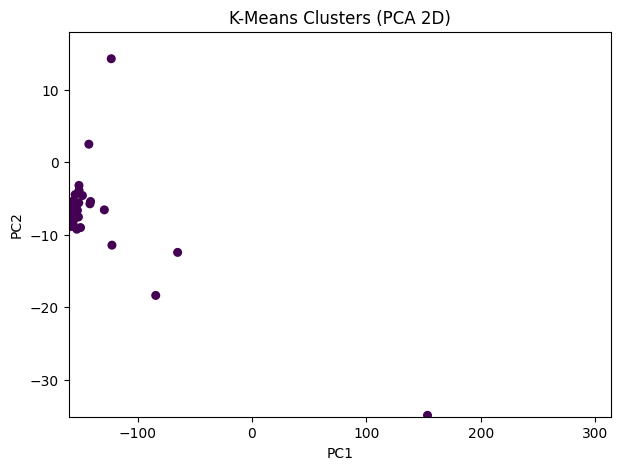

In [ ]:
# ----------------------------
# 5) K-MEANS: select best K by Silhouette (tie-break lower DB)
# ----------------------------
# Try multiple K values and choose the best clustering using internal metrics:
# - Silhouette (higher is better)
# - Davies-Bouldin (lower is better) as a tie-breaker
max_k = min(15, n_tickers - 1)
k_values = list(range(2, max_k + 1))

km_scores = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_pca)

    sil = silhouette_score(X_pca, labels)
    db = davies_bouldin_score(X_pca, labels)
    km_scores.append((k, sil, db))

# Rank candidate K values by quality metrics
km_scores_df = pd.DataFrame(km_scores, columns=["k", "silhouette", "davies_bouldin"])
km_scores_df = km_scores_df.sort_values(by=["silhouette", "davies_bouldin"], ascending=[False, True])

print("\n[K-Means] Model selection:")
print(km_scores_df)

# Fit final K-Means using the best K
best_k = int(km_scores_df.iloc[0]["k"])
kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)
ticker_df["Cluster_KMeans"] = kmeans_labels

print(f"\nK-Means best k = {best_k}")
print(ticker_df["Cluster_KMeans"].value_counts().sort_index())

# Report metrics + visualize clusters in 2D PCA space
clustering_metrics(f"K-Means (k={best_k})", X_pca, kmeans_labels)
plot_clusters("K-Means Clusters (PCA 2D)", X_2d, kmeans_labels)


[GMM] Model selection:
     k          bic          aic  silhouette  davies_bouldin
11  13   859.209032   733.872972    0.545090        0.193188
13  15   864.155007   719.029043    0.564871        0.175145
12  14   874.425920   739.194908    0.579615        0.157124
10  12   876.683945   761.242837    0.576016        0.193215
9   11   878.136430   772.590274    0.575892        0.195809
8   10   898.189262   802.538059    0.581936        0.237512
7    9   940.837390   855.081139    0.710239        0.219730
6    8   954.212954   878.351655    0.751033        0.241193
5    7   978.683128   912.716781    0.757072        0.312808
4    6   989.162405   933.091010    0.797680        0.359873
3    5  1010.368209   964.191766    0.820419        0.481510
2    4  1024.209137   987.927646    0.824275        0.595699
1    3  2096.350787  2069.964248    0.985465        0.002676
0    2  2777.709255  2761.217668    0.993114        0.001658

GMM best k = 13
Cluster_GMM
0     67
1      1
2      1
3    

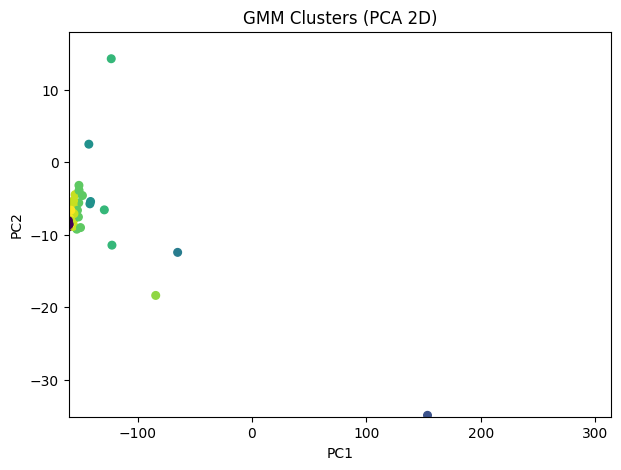

In [ ]:
# ----------------------------
# 6) GMM: select best components by BIC (quality check silhouette)
#    Add reg_covar + n_init for stability (prevents rare covariance issues)
# ----------------------------
# Gaussian Mixture Model (soft clustering):
# - Select number of components using BIC (lower is better) with AIC as reference
# - Also compute Silhouette/DB for a clustering-quality check
# - reg_covar + n_init improve stability (avoid singular covariance + reduce randomness)
gmm_scores = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=SEED,
        reg_covar=1e-6,
        n_init=3
    )
    gmm.fit(X_pca)
    labels = gmm.predict(X_pca)

    bic = gmm.bic(X_pca)
    aic = gmm.aic(X_pca)
    sil = silhouette_score(X_pca, labels)
    db = davies_bouldin_score(X_pca, labels)

    gmm_scores.append((k, bic, aic, sil, db))

# Rank candidate component counts (primary: BIC, secondary: silhouette)
gmm_scores_df = pd.DataFrame(gmm_scores, columns=["k", "bic", "aic", "silhouette", "davies_bouldin"])
gmm_scores_df = gmm_scores_df.sort_values(by=["bic", "silhouette"], ascending=[True, False])

print("\n[GMM] Model selection:")
print(gmm_scores_df)

# Fit final GMM with best number of components
best_k_gmm = int(gmm_scores_df.iloc[0]["k"])
gmm_best = GaussianMixture(
    n_components=best_k_gmm,
    covariance_type="full",
    random_state=SEED,
    reg_covar=1e-6,
    n_init=3
)
gmm_best.fit(X_pca)

# Final cluster labels + confidence (max membership probability per ticker)
gmm_labels = gmm_best.predict(X_pca)
gmm_conf = gmm_best.predict_proba(X_pca).max(axis=1)

ticker_df["Cluster_GMM"] = gmm_labels
ticker_df["GMM_MaxProb"] = gmm_conf

print(f"\nGMM best k = {best_k_gmm}")
print(ticker_df["Cluster_GMM"].value_counts().sort_index())

# Report metrics + visualize clusters
clustering_metrics(f"GMM (k={best_k_gmm})", X_pca, gmm_labels)
plot_clusters("GMM Clusters (PCA 2D)", X_2d, gmm_labels)

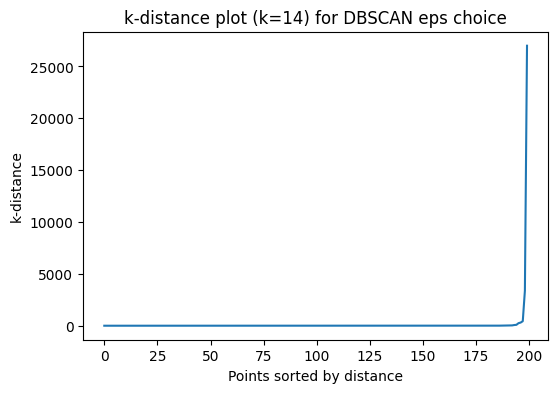


[DBSCAN] Parameters:
min_samples = 14 | eps = 2.744954201247822
DBSCAN clusters = 1 | noise points = 15

MODEL: DBSCAN
Clusters (excluding noise): 1
Noise points: 15 (7.50%)
Silhouette / DB / CH: N/A (need >=2 clusters excluding noise)


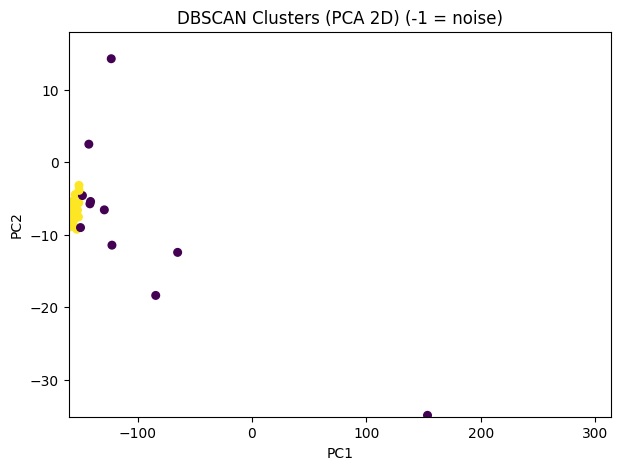


DBSCAN Outlier tickers (first 30): ['AUDAQ', 'BIMI', 'CLRB', 'CRDE', 'ECGR', 'GCTK', 'LMFA', 'MELI', 'NVAX', 'NVFY', 'OPGN', 'ROII', 'SLS', 'VTLE', 'VTVT'] 


In [ ]:
# ----------------------------
# 7) DBSCAN: eps via k-distance curve + percentile start
# ----------------------------
# DBSCAN is density-based and can mark outliers as noise (-1).
# We estimate eps using the k-distance curve (common practice for DBSCAN tuning).
min_samples = max(5, int(np.sqrt(n_tickers)))

# Compute k-nearest neighbor distances (k = min_samples)
nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
k_dist = np.sort(distances[:, -1])

# Plot k-distance to justify eps choice (visible "elbow" suggests a good eps)
plt.figure(figsize=(6, 4))
plt.plot(k_dist)
plt.title(f"k-distance plot (k={min_samples}) for DBSCAN eps choice")
plt.xlabel("Points sorted by distance")
plt.ylabel("k-distance")
plt.show()

# Start with a high-percentile k-distance as an automatic eps guess
eps = float(np.percentile(k_dist, 90))
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_pca)
ticker_df["Cluster_DBSCAN"] = dbscan_labels

# Summarize clusters and noise points
uniq = set(dbscan_labels)
n_noise = int((dbscan_labels == -1).sum())
n_clusters_db = len(uniq) - (1 if -1 in uniq else 0)

print("\n[DBSCAN] Parameters:")
print("min_samples =", min_samples, "| eps =", eps)
print("DBSCAN clusters =", n_clusters_db, "| noise points =", n_noise)

# Report metrics + visualize clusters (noise excluded in metrics)
clustering_metrics("DBSCAN", X_pca, dbscan_labels)
plot_clusters("DBSCAN Clusters (PCA 2D) (-1 = noise)", X_2d, dbscan_labels)

# List outlier tickers identified as noise (useful for report discussion)
if n_noise > 0:
    outliers = ticker_df.loc[ticker_df["Cluster_DBSCAN"] == -1, "Ticker"].tolist()
    print("\nDBSCAN Outlier tickers (first 30):", outliers[:30], "..." if len(outliers) > 30 else "")

In [ ]:
# ----------------------------
# 8) Quick interpretation (samples per cluster)
# ----------------------------
# Print a few example tickers from each cluster to help interpret cluster meaning
# (useful for discussing cluster behavior in the report)
print("\nSample tickers per K-Means cluster:")
for cl in sorted(np.unique(kmeans_labels)):
    sample = ticker_df.loc[ticker_df["Cluster_KMeans"] == cl, "Ticker"].head(10).tolist()
    print(f"KMeans Cluster {cl}: {sample}")

print("\nSample tickers per GMM cluster:")
for cl in sorted(np.unique(gmm_labels)):
    sample = ticker_df.loc[ticker_df["Cluster_GMM"] == cl, "Ticker"].head(10).tolist()
    print(f"GMM Cluster {cl}: {sample}")

print("\nSample tickers per DBSCAN label (including -1 noise):")
for cl in sorted(np.unique(dbscan_labels)):
    sample = ticker_df.loc[ticker_df["Cluster_DBSCAN"] == cl, "Ticker"].head(10).tolist()
    print(f"DBSCAN Label {cl}: {sample}")


Sample tickers per K-Means cluster:
KMeans Cluster 0: ['AAME', 'ABTS', 'AEP', 'AILIN', 'AIRG', 'AKO-A', 'ALE', 'ALSMY', 'ARE', 'ASG']
KMeans Cluster 1: ['OPGN']

Sample tickers per GMM cluster:
GMM Cluster 0: ['AAME', 'AILIN', 'AKO-A', 'ALSMY', 'ASG', 'ASRMF', 'BBDC', 'BCS', 'BFC', 'BGC']
GMM Cluster 1: ['OPGN']
GMM Cluster 2: ['SLS']
GMM Cluster 3: ['LMFA']
GMM Cluster 4: ['ROII']
GMM Cluster 5: ['BIMI']
GMM Cluster 6: ['ECGR', 'GCTK', 'VTLE']
GMM Cluster 7: ['CRDE']
GMM Cluster 8: ['AUDAQ', 'MELI', 'VTVT']
GMM Cluster 9: ['CACI', 'DAC', 'NVAX', 'NVFY', 'SPG', 'STRA', 'UNH', 'ZBRA']
GMM Cluster 10: ['CLRB']
GMM Cluster 11: ['ABTS', 'ALE', 'ARE', 'ASGN', 'BCTX', 'BJRI', 'BXC', 'CLW', 'CVGW', 'DBVT']
GMM Cluster 12: ['AEP', 'AIRG', 'ASIX', 'AVXL', 'BEP', 'BLDP', 'BUDZ', 'CARE', 'CLMT', 'CPF']

Sample tickers per DBSCAN label (including -1 noise):
DBSCAN Label -1: ['AUDAQ', 'BIMI', 'CLRB', 'CRDE', 'ECGR', 'GCTK', 'LMFA', 'MELI', 'NVAX', 'NVFY']
DBSCAN Label 0: ['AAME', 'ABTS', 'AEP', 'A

In [ ]:
import numpy as np
import pandas as pd

def cluster_profile_table(df, cluster_col, metrics, top_n_clusters=None, sample_n=5):
    # keep only rows with a label
    d = df.dropna(subset=[cluster_col]).copy()

    # ensure metrics exist
    metrics = [m for m in metrics if m in d.columns]
    if len(metrics) == 0:
        raise ValueError(f"No metric columns found in df for profiling. Tried: {metrics}")

    total = d.shape[0]

    # base summary
    grp = d.groupby(cluster_col, dropna=False)
    summary = grp.agg(
        N=("Ticker", "count"),
        **{m: (m, "mean") for m in metrics}
    ).reset_index().rename(columns={cluster_col: "Cluster ID"})

    summary["% of tickers"] = (summary["N"] / total * 100).round(2)

    # sample tickers
    samples = (
        grp["Ticker"]
        .apply(lambda s: ", ".join(s.head(sample_n).astype(str).tolist()))
        .reset_index()
        .rename(columns={"Ticker": f"Example tickers (1–{sample_n})", cluster_col: "Cluster ID"})
    )
    summary = summary.merge(samples, on="Cluster ID", how="left")

    # simple auto-interpretation (based on relative volatility/price-range/volume-change)
    # You can edit these 1-line interpretations after generation if you want.
    def interpret_row(r):
        vol = r.get("STD_5_mean", np.nan)
        pr  = r.get("Price_Range_mean", np.nan)
        vc  = r.get("Volume_Change_mean", np.nan)
        ret = r.get("Daily_Return_mean", np.nan)

        parts = []
        if not np.isnan(vol):
            parts.append("High volatility" if vol >= summary["STD_5_mean"].median() else "Low volatility")
        if not np.isnan(pr):
            parts.append("wide price range" if pr >= summary["Price_Range_mean"].median() else "narrow price range")
        if not np.isnan(vc):
            parts.append("high volume-change" if vc >= summary["Volume_Change_mean"].median() else "stable volume")
        if not np.isnan(ret):
            parts.append("positive drift" if ret > 0 else "negative/flat drift")

        return ", ".join(parts[:3]) + (f" ({parts[3]})" if len(parts) > 3 else "")

    summary["Interpretation (1 line)"] = summary.apply(interpret_row, axis=1)

    # optionally keep only largest clusters (useful for GMM=13)
    summary = summary.sort_values("N", ascending=False)
    if top_n_clusters is not None:
        summary = summary.head(top_n_clusters)

    # reorder columns for report
    cols_order = ["Cluster ID", "N", "% of tickers"] + metrics + [f"Example tickers (1–{sample_n})", "Interpretation (1 line)"]
    summary = summary[cols_order]

    return summary

# ---- Choose the metrics you want in your report tables (based on your engineered features) ----
metrics_for_report = ["Daily_Return_mean", "STD_5_mean", "Price_Range_mean", "Volume_Change_mean"]

# ---- K-Means profiling (typically small K like 2) ----
kmeans_profile = cluster_profile_table(ticker_df, "Cluster_KMeans", metrics_for_report, sample_n=5)
display(kmeans_profile)

# ---- DBSCAN profiling (include noise -1) ----
dbscan_profile = cluster_profile_table(ticker_df, "Cluster_DBSCAN", metrics_for_report, sample_n=5)
display(dbscan_profile)

# ---- GMM profiling (13 clusters is long: show top 5 biggest clusters for report) ----
gmm_profile_top5 = cluster_profile_table(ticker_df, "Cluster_GMM", metrics_for_report, top_n_clusters=5, sample_n=5)
display(gmm_profile_top5)

# ---- Save tables to CSV so you can copy numbers into Word easily ----
kmeans_profile.to_csv("table_kmeans_cluster_profile.csv", index=False)
dbscan_profile.to_csv("table_dbscan_cluster_profile.csv", index=False)
gmm_profile_top5.to_csv("table_gmm_top5_cluster_profile.csv", index=False)

print("Saved profiling tables:",
      "table_kmeans_cluster_profile.csv, table_dbscan_cluster_profile.csv, table_gmm_top5_cluster_profile.csv")

,Cluster ID,N,% of tickers,Daily_Return_mean,STD_5_mean,Price_Range_mean,Volume_Change_mean,Example tickers (1–5),Interpretation (1 line)
0,0,199,99.5,0.00423,2.773851,3.495227,2.915048,"AAME, ABTS, AEP, AILIN, AIRG","Low volatility, narrow price range, high volum..."
1,1,1,0.5,-0.00165,2268.801072,4423.036613,1.349522,OPGN,"High volatility, wide price range, stable volu..."


,Cluster ID,N,% of tickers,Daily_Return_mean,STD_5_mean,Price_Range_mean,Volume_Change_mean,Example tickers (1–5),Interpretation (1 line)
1,0,185,92.5,0.004324,0.466075,0.677973,2.997521,"AAME, ABTS, AEP, AILIN, AIRG","Low volatility, narrow price range, high volum..."
0,-1,15,7.5,0.002681,182.304900,332.877448,1.793514,"AUDAQ, BIMI, CLRB, CRDE, ECGR","High volatility, wide price range, stable volu..."


,Cluster ID,N,% of tickers,Daily_Return_mean,STD_5_mean,Price_Range_mean,Volume_Change_mean,Example tickers (1–5),Interpretation (1 line)
12,12,72,36.0,0.001178,0.364881,0.523516,0.817781,"AEP, AIRG, ASIX, AVXL, BEP","Low volatility, narrow price range, stable vol..."
0,0,67,33.5,0.010157,0.098523,0.115271,7.184852,"AAME, AILIN, AKO-A, ALSMY, ASG","Low volatility, narrow price range, high volum..."
11,11,40,20.0,0.000738,1.011139,1.489208,0.329270,"ABTS, ALE, ARE, ASGN, BCTX","Low volatility, narrow price range, stable vol..."
9,9,8,4.0,0.001174,2.064240,3.273144,0.428923,"CACI, DAC, NVAX, NVFY, SPG","Low volatility, narrow price range, stable vol..."
6,6,3,1.5,0.009922,3.585493,3.418620,3.877635,"ECGR, GCTK, VTLE","Low volatility, narrow price range, high volum..."


Saved profiling tables: table_kmeans_cluster_profile.csv, table_dbscan_cluster_profile.csv, table_gmm_top5_cluster_profile.csv


In [ ]:
# ----------------------------
# 9) Save results
# ----------------------------
# Save ticker-level clustering output for submission/report analysis
out_path = "/content/drive/MyDrive/unsupervised_clusters_ticker_level.csv"
try:
    ticker_df.to_csv(out_path, index=False)
    print("\nSaved:", out_path)
except Exception as e:
    # If Drive is not mounted or path is not accessible, saving will fail
    print("\nCould not save to Drive path. If Drive not mounted, mount it first.")
    print("Error:", e)


Saved: /content/drive/MyDrive/unsupervised_clusters_ticker_level.csv
